## Motivation and Problem Statement


**Problem statement**

Only part of the visitors who enter an online store end up buying. Every session that ends without a purchase is a lost sale, but offering a discount to every visitor is not a solution either: it lowers the margin on sales that would have happened anyway. The company therefore needs to know, session by session, how likely a visit is to end in a purchase.

**Our goal**

The goal of this project is to build a model that effectively predicts whether an online session will end in a purchase, and to identify which browsing behaviours carry the most weight in that prediction. The company can then decide, based on its own margins and strategy, whether to intervene (for example with a discount) and how.

**Use for the business**

The predicted probability can help the business prioritise sessions or design interventions. Deciding whether an intervention is worthwhile, depends on margins and campaign costs that are not part of this dataset, so that decision is left to the company.




### How Machine Learning techniques will be beneficial

Our target is `revenue`, which tells us whether each past session ended in a purchase or not. It is a binary option where we could categorize each session in "ended in purchase" or "not ended in purchase". This makes the problem a Supervised Classification task. In this case, the model learns from the behaviour recorded in past sessions (pages visited, time spent, bounce, etc) and, for a new session, estimates the whether it ends in a purchase or not.

On the other hand, other machine learning techniques like regression does not apply because the dataset has no continuous target such as an order value and clustering is not needed to answer our question.

## How are we going to implement the model?

We will have the CRISP-DM process model as a reference to structure this project. The six phases are: business understanding, data understanding, data preparation, modelling, evaluation and deployment.

Business understanding is covered here at a high level only, because we do not have information on margins, campaign costs or business constraints. Data understanding and data preparation correspond to the exploratory data analysis and preprocessing, modelling and evaluation correspond to the training and comparison of the models, and the conclusions close the cycle. Deployment is outside the scope of this project, since the model will not be put into production.

<img src="Sin título.jpg" width="300">

#### Data understanding

These tasks describe the data and verify its quality, without modifying it.

| Task | What we will do | Why it is relevant |
|---|---|---|
| Missing values | Check every column for missing values. | Most models cannot train on missing values. |
| Duplicate rows | Check for repeated records and assess whether they are errors or legitimate observations. | Duplicated errors would give some observations extra weight in training. |
| Consistency and units | Verify the meaning and units of each variable and look for impossible values. | Wrong units or values would lead to misleading features. |
| Data types | Review whether each variable is numeric, categorical or boolean. | Some variables stored as numbers may only be labels with no order. |
| Outliers and distributions | Inspect the distributions, for example with histograms, Heatmaps and Pairplots. | Extreme values can distort models that depend on distances or coefficients. |
| Class balance | Count how many sessions belong to each class of the target. | Determines whether the classes are balanced and which metrics and techniques are appropriate. |

#### Data preparation

These tasks modify the data based on what the previous checks reveal.

| Task | What we will do | Why it is relevant |
|---|---|---|
| Cleaning | Remove or impute missing values, and decide whether to keep or drop duplicates and how to treat outliers. | Gives the models consistent and reliable inputs. |
| Formatting | Set the right data types and convert the target to 0/1. | Models need correctly typed inputs and a numeric target. |
| Encoding | Convert categorical variables to numbers with one-hot encoding. | Avoids creating a false order between categories. |
| Scaling | Standardise the numeric features | Features with very different ranges can dominate models based on distances or gradients, such as logistic regression and KNN. |

#### Modelling

| Task | What we will do | Why it is relevant |
|---|---|---|
| Test design | Split the data once with a stratified train/test split, before fitting any preprocessing step. | Gives an honest evaluation on observations the model has never seen. |
| Pipelines | Build one pipeline per model so that encoding and scaling are fitted only on training data. | Prevents information from the test set from influencing training. |
| Cross-validation and tuning | Compare several classifiers with stratified cross-validation and tune their hyperparameters. | Gives a fair comparison between models and reduces the risk of overfitting. |
| Class imbalance handling | If the classes are imbalanced, apply resampling (for example SMOTE) only to the training data of each cross-validation fold. | Prevents the models from favouring the majority class, and avoids leakage by never resampling the validation or test data. |

#### Evaluation

| Task | What we will do | Why it is relevant |
|---|---|---|
| Multiple metrics | Use ROC-AUC, average precision, F1, and recall and precision of the purchase class. | Accuracy alone can be misleading if the classes are not balanced. |
| Interpretation | Rank features by their weight in the model and check whether any one dominates. | Shows which behaviours are associated with a purchase and whether a variable may leak the outcome. |


In [55]:
from sklearn.datasets import load_iris
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data Understanding

In [56]:
# Retrieving the data
shoppers_intention_df = pd.read_csv('online_shoppers_intention.csv')

In [57]:
shoppers_intention_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

## Data Sctructure

| Feature | Description |
|---|---|
| `Administrative` | Number of administrative pages (Ex. Login, Address) visited by the visitor in that session |
| `Administrative_Duration` | Total time spent on administrative pages (Ex. Login, Address) |
| `Informational` | Number of informational pages (Ex. Contact, Help) visited by the visitor in that session |
| `Informational_Duration` | Total time spent on informational pages (Ex. Contact, Help) |
| `ProductRelated` | Number of product-related pages (Ex. Product Description and price) visited by the visitor in that session |
| `ProductRelated_Duration` | Total time spent on product-related pages (Ex. Product Description and price) |
| `BounceRates` | Percentage of visitors who enter the site and then leave ("bounce") that session (only visits one specific page and then leaves). This is measured by Google Analytics |
| `ExitRates` | Of all pageviews to the page, the percentage that were the last in the session(measured by Google Analytics) |
| `PageValues` | Average value (measured by Google Analytics) of the pages visited in the session, based on how much revenue those pages have historically been associated with before a purchase |
| `SpecialDay` | Closeness of the visit to a specific special day (e.g. Mother's Day, Valentine's Day), when sessions are more likely to end in a transaction |
| `Revenue` | Target variable: whether the session ended in a purchase (`True`) or not (`False`) || `Month` | Month of the year in which the visit took place |
| `OperatingSystems` | Numeric code of the visitor's operating system |
| `Browser` | Numeric code of the visitor's browser |
| `Region` | Numeric code of the visitor's geographic region |
| `TrafficType` | Numeric code of the traffic source |
| `VisitorType` | Type of visitor: `New_Visitor`, `Returning_Visitor` or `Other` |
| `Weekend` | `True` if the visit took place on a weekend |


| Columns | Data type | Variable type |
|---|---|---|
| `Administrative`, `Informational`, `ProductRelated` | int64 | Numerical (discrete) |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | int64 | Categorical (nominal) |
| `Administrative_Duration`, `Informational_Duration`, `ProductRelated_Duration`, `BounceRates`, `ExitRates`, `PageValues` | float64 | Numerical (continuous) |
| `SpecialDay` | float64 | Numerical (6 discrete values between 0 and 1) |
| `Month` | str | Categorical (ordinal) |
| `VisitorType` | str | Categorical (nominal) |
| `Weekend` | bool | Binary |
| `Revenue` | bool | Binary |

In [58]:
shoppers_intention_df.head(1)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False


**What does a row mean?**

Each row represents one browsing session on an e-commerce website. According to the dataset documentation, the data was built so that each session belongs to a different user within a one-year period, so rows can be treated as independent visits.

For each session, the dataset records the type and number of pages visited and the time spent on them, Google Analytics metrics (bounce rate, exit rate and page value), the closeness of the visit to a special day, the month, whether it was a weekend, technical information (operating system, browser, region and traffic type) and the type of visitor (new or returning).

These are the features used to analyze and predict, among other things, whether a session ends in a purchase, which is reflected in the `Revenue` column.

In [59]:
display(shoppers_intention_df.describe())
display(shoppers_intention_df.isna().sum())


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,"12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0"
mean,2.3,80.8,0.5,34.5,31.7,"1,194.7",0.0,0.0,5.9,0.1,2.1,2.4,3.1,4.1
std,3.3,176.8,1.3,140.7,44.5,"1,913.7",0.0,0.0,18.6,0.2,0.9,1.7,2.4,4.0
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0
25%,0.0,0.0,0.0,0.0,7.0,184.1,0.0,0.0,0.0,0.0,2.0,2.0,1.0,2.0
50%,1.0,7.5,0.0,0.0,18.0,598.9,0.0,0.0,0.0,0.0,2.0,2.0,3.0,2.0
75%,4.0,93.3,0.0,0.0,38.0,"1,464.2",0.0,0.1,0.0,0.0,3.0,2.0,4.0,4.0
max,27.0,"3,398.8",24.0,"2,549.4",705.0,"63,973.5",0.2,0.2,361.8,1.0,8.0,13.0,9.0,20.0


Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

**Interpretation of Summary Statistics**

- **Complete data**
  - the `count` row is 12,330 in every column, which equals the total number of rows. If a value were missing, `count` would be lower than 12,330 for that column.
  - The absence of missing values is confirmed with `isna().sum()`.

- **Mean much larger than the median (right-skewed distributions)**

    *Columns:* `Administrative`, `Administrative_Duration`, `Informational`, `Informational_Duration`, `ProductRelated`, `ProductRelated_Duration`, `BounceRates`, `ExitRates`, `PageValues`.

    1. The mean uses every value, so a few very large ones raise it. The median is the middle value and does not depend on how large the extremes are. In a symmetric distribution both are similar.
    2. In these columns the mean is above the median (ex. `ProductRelated_Duration`: mean = 1,195 vs median = 599; `Administrative_Duration`: mean = 81 vs median 7.5).
    3. The maximum is also far from the 75th percentile (ex. `ProductRelated_Duration`: max = 63,974 vs 75th percentile = 1,464), which means the large values are few and extreme.
    4. The standard deviation is larger than the mean in all of these columns (ex. `ProductRelated_Duration`: = 1,914 vs = 1,195), which also indicates high dispersion.

    **Some columns are not interpretable**
    Columns: `OperatingSystems`,`Browser`,`Region`,`TrafficType`

    These features have encoded and anonimized data that we are not able to interpret. 

   ### General Insights:
    - a few very long or very active sessions pull the mean up, so the median describes a typical session better.
    - Some columns may offer good insight about the session but do not provide enough information to be interpret.


## Renaming Columns


The columns have different naming structure as some of them use camel case and others snake case. We consider appropiate to have a standarized naming nomenclature. 
We chose to apply snake case to all column names and variables.

In [60]:
shoppers_intention_df = shoppers_intention_df.rename(columns={
    'Administrative': 'administrative',
    'Administrative_Duration': 'administrative_duration',
    'Informational': 'informational',
    'Informational_Duration': 'informational_duration',
    'ProductRelated': 'product_related',
    'ProductRelated_Duration': 'product_related_duration',
    'BounceRates': 'bounce_rates',
    'ExitRates': 'exit_rates',
    'PageValues': 'page_values',
    'SpecialDay': 'special_day',
    'Month': 'month',
    'OperatingSystems': 'operating_systems',
    'Browser': 'browser',
    'Region': 'region',
    'TrafficType': 'traffic_type',
    'VisitorType': 'visitor_type',
    'Weekend': 'weekend',
    'Revenue': 'revenue'
})
shoppers_intention_df.head()

,administrative,administrative_duration,informational,informational_duration,product_related,product_related_duration,bounce_rates,exit_rates,page_values,special_day,month,operating_systems,browser,region,traffic_type,visitor_type,weekend,revenue
0,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.0,0.0,0.1,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.7,0.1,0.1,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.5,0.0,0.1,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### Verifying the uniqueness of the data

In [61]:
print(f" Amount of duplicated session: {shoppers_intention_df.duplicated().sum()} (without counting the first of the group)")

dupplicated_sessions = shoppers_intention_df[shoppers_intention_df.duplicated(keep=False)]
print("\n Duplicates counting the first of the group:")
dupplicated_sessions.sort_values(list(shoppers_intention_df.columns))

 Amount of duplicated session: 125 (without counting the first of the group)

 Duplicates counting the first of the group:


,administrative,administrative_duration,informational,informational_duration,product_related,product_related_duration,bounce_rates,exit_rates,page_values,special_day,month,operating_systems,browser,region,traffic_type,visitor_type,weekend,revenue
8247,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,1,Returning_Visitor,True,False
10751,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,1,Returning_Visitor,True,False
11658,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,1,Returning_Visitor,True,False
8882,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,2,New_Visitor,False,False
11934,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,2,New_Visitor,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2423,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,May,2,2,2,3,Returning_Visitor,False,False
4552,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,May,2,2,2,3,Returning_Visitor,False,False
5199,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,May,2,2,2,3,Returning_Visitor,False,False
9715,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Nov,1,1,1,1,Returning_Visitor,False,False


We check for duplicated rows to make sure there is no massive number of identical records, which could indicate a data collection or loading error. The dataset contains 125 duplicated rows (about 1% of the 12,330 sessions), so there is no evidence of a large-scale duplication problem.

We also consider it plausible that two different sessions have exactly the same values. Many sessions are very short (for example, a visitor who opens a single page and leaves), and these sessions can easily coincide in all of their features. In addition, the dataset documentation states that each session belongs to a different user, so identical rows are not necessarily the same session recorded twice.

Given the small number of duplicated rows and the plausibility of identical sessions, we decided not to drop them. Removing them would change the dataset very little (12,330 rows vs. 12,205), and we could discard valid sessions.

### Checking the unit of the duration columns

The official dataset documentation does not state the unit of the duration columns (`administrative_duration`, `informational_duration` and `product_related_duration`). We assume they are measured in seconds but we check whether that this assumption is plausible using `product_related_duration`.

**What this code does**

1. **Time per page:** keep only the sessions that visited product pages and have a recorded duration, divide the total duration by the number of pages and take the median. If the unit is seconds, the result is the typical number of seconds spent on each page.
2. **Smallest positive values:** list the smallest durations greater than 0, to see whether they are realistic times for a single visit.



In [62]:
# Keep only the sessions that visited product pages and have a recorded duration
visited = shoppers_intention_df[
    (shoppers_intention_df["product_related"] > 0) &
    (shoppers_intention_df["product_related_duration"] > 0)
]

# Total time divided by the number of pages = time per page
time_per_page = visited["product_related_duration"] / visited["product_related"]
# Using the median because is more representative of the data
print(f"Median time spent per product page: {time_per_page.median()}")

# Check what are the smallest positive values
positive_values = shoppers_intention_df[shoppers_intention_df["product_related_duration"] > 0]["product_related_duration"]
print(f"\n List of the shortest duration spent on product pages: ")
display(positive_values.sort_values().head())

Median time spent per product page: 30.325

 List of the shortest duration spent on product pages: 


11565   0.5
1450    1.0
5256    1.0
2569    2.3
3       2.7
Name: product_related_duration, dtype: float64

**Interpretation**

- The median time per page is about 30. In seconds, this means a typical visitor spends about 30 seconds on each product page, which is realistic. In milliseconds it would be 0.03 seconds per page, and in minutes it would be 30 minutes per page; neither makes sense.
- Smallest positive values: 0.5, 1, 1, 2.33 and 2.67. In seconds, these are very short visits. In milliseconds, they would be impossible reading times.

Both results are consistent with seconds. This is a plausibility check, not a confirmation, because the unit is not recorded in the dataset. Hovever, from now on the duration values will be interpreted as seconds.

In [63]:
# Format floats to be easier to read, including the duration columns
pd.options.display.float_format = "{:,.1f}".format
shoppers_intention_df.describe()

,administrative,administrative_duration,informational,informational_duration,product_related,product_related_duration,bounce_rates,exit_rates,page_values,special_day,operating_systems,browser,region,traffic_type
count,"12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0","12,330.0"
mean,2.3,80.8,0.5,34.5,31.7,"1,194.7",0.0,0.0,5.9,0.1,2.1,2.4,3.1,4.1
std,3.3,176.8,1.3,140.7,44.5,"1,913.7",0.0,0.0,18.6,0.2,0.9,1.7,2.4,4.0
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0
25%,0.0,0.0,0.0,0.0,7.0,184.1,0.0,0.0,0.0,0.0,2.0,2.0,1.0,2.0
50%,1.0,7.5,0.0,0.0,18.0,598.9,0.0,0.0,0.0,0.0,2.0,2.0,3.0,2.0
75%,4.0,93.3,0.0,0.0,38.0,"1,464.2",0.0,0.1,0.0,0.0,3.0,2.0,4.0,4.0
max,27.0,"3,398.8",24.0,"2,549.4",705.0,"63,973.5",0.2,0.2,361.8,1.0,8.0,13.0,9.0,20.0


### Are the classes balanced?


Class distribution:
revenue
False    10422
True      1908
Name: count, dtype: int64


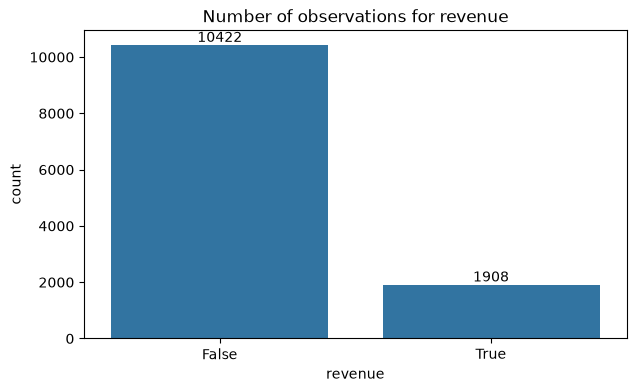

In [64]:
print("Class distribution:")
print(shoppers_intention_df["revenue"].value_counts().sort_index())

plt.figure(figsize=(7, 4))
ax = sns.countplot(data=shoppers_intention_df, x="revenue")
# Shows the exact number
ax.bar_label(ax.containers[0], fmt="%d")
plt.title("Number of observations for revenue")
plt.show()

### The classes are imbalanced

The dataset is imbalanced: 10,422 sessions (84.5%) did not end in a purchase, while only 1,908 sessions (15.5%) did. In other words, sessions without a purchase are about 5.5 times more frequent than sessions with a purchase.

The model could always predict "no purchase" and be right about 84.5% of the time while never identifying a single buyer, so accuracy hides the failure that matters most. In addition, most algorithms try to reduce the overall error, which is dominated by the majority class, and they have far fewer purchase examples to learn from. 
As a result, the model tends to miss purchases and to give them low probabilities.

To address this issue, a balancing method such as class weighting or SMOTE will be applied during training in the modelling phase.


## Visualizing the features

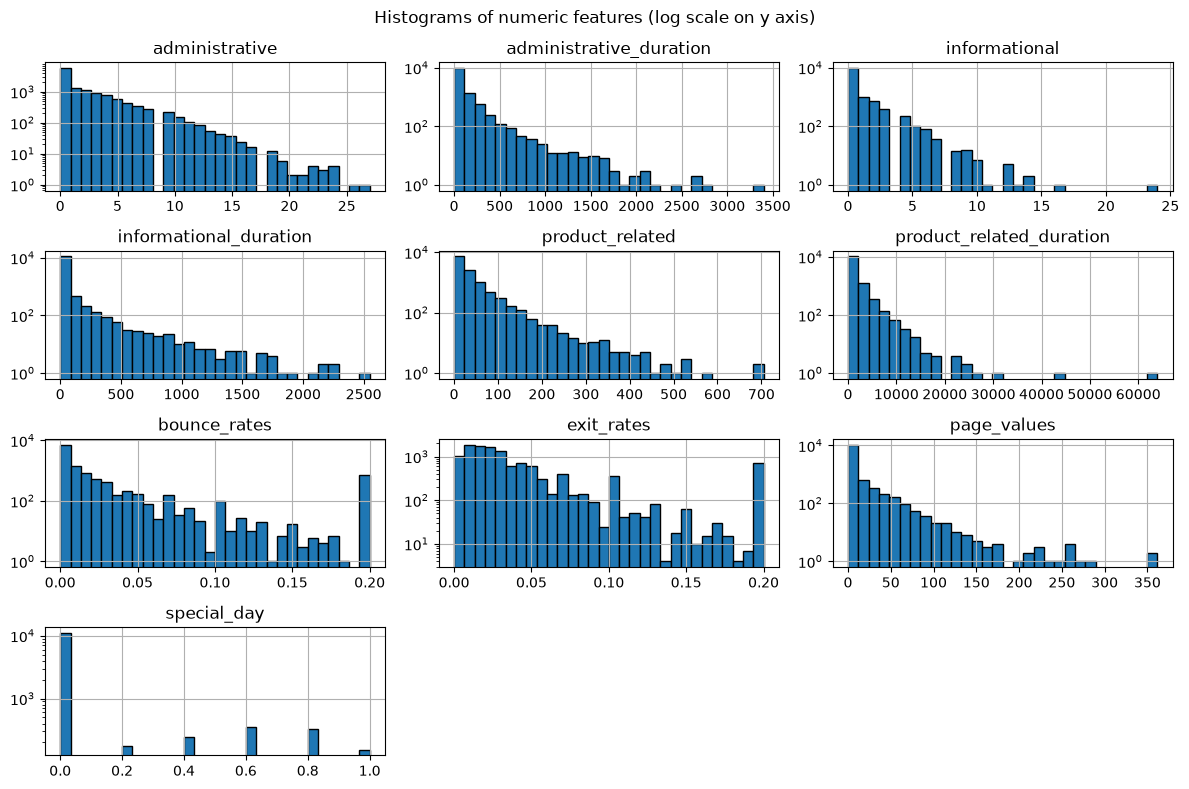

In [65]:
numeric_columns = [
    "administrative", "administrative_duration",
    "informational", "informational_duration",
    "product_related", "product_related_duration",
    "bounce_rates", "exit_rates", "page_values", "special_day",
]
categorical_columns = [
    "month", "operating_systems", "browser", "region",
    "traffic_type", "visitor_type", "weekend", "revenue",
]


shoppers_intention_df[numeric_columns].hist(figsize=(12, 8), bins=30, edgecolor="black", log=True)
plt.suptitle("Histograms of numeric features (log scale on y axis)")
plt.tight_layout()
plt.show()

#### Interpretation of the histograms

Almost all numeric variables are strongly right-skewed. Most sessions show little activity, while a small number of sessions are very long or visit many pages. The y axis uses a logarithmic scale, so bars with very few sessions remain visible.

**Page counts and durations** (administrative, informational, product_related and their duration):

A large number of sessions are at or near zero, followed by a long tail. For example, product_related reaches about 700 pages and product_related_duration about 64,000 seconds, with only a few sessions at the highest values. These sessions will, most likely, be categorized as outliers.

## Correlation Heatmap and Pairplot (DRAFT)



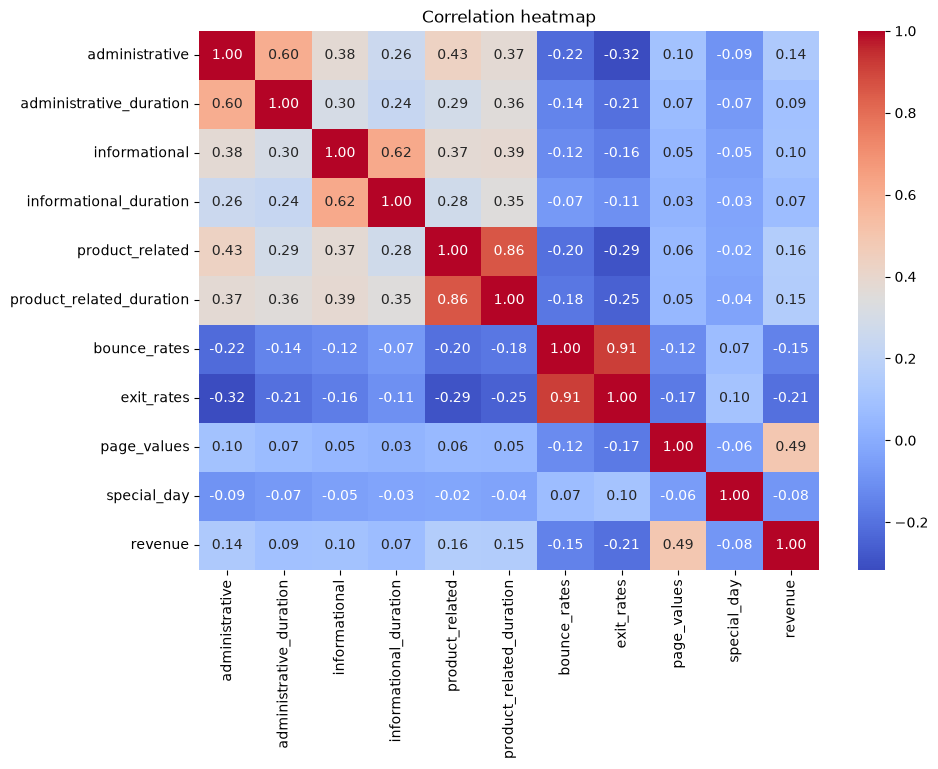

In [66]:
# Numeric columns + the target as 0/1 (on a copy, the original is unchanged)
data_encoded = shoppers_intention_df[numeric_columns].copy()
data_encoded["revenue"] = shoppers_intention_df["revenue"].astype(int)

correlation_matrix = data_encoded.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

### Pairplot (DRAFT)

### Shopping Sessions Relative to Total Sessions per Month

In [67]:
counts = (
    shoppers_intention_df.groupby("month")
    .size()
    .rename("observations")
    .reset_index()
)

revenue = (
    shoppers_intention_df.groupby("month")["revenue"]
    .sum()
    .rename("total_revenue")
    .reset_index()
)

Shopping_months = counts.merge(
    revenue,
    on="month",
    how="inner",
    validate="one_to_one"
)

order = [2, 5, 6, 4, 3, 0, 9, 8, 7, 1]

shopping_months_order = Shopping_months.reindex(order)
shopping_months_order

,month,observations,total_revenue
2,Feb,184,3
5,Mar,1907,192
6,May,3364,365
4,June,288,29
3,Jul,432,66
0,Aug,433,76
9,Sep,448,86
8,Oct,549,115
7,Nov,2998,760
1,Dec,1727,216


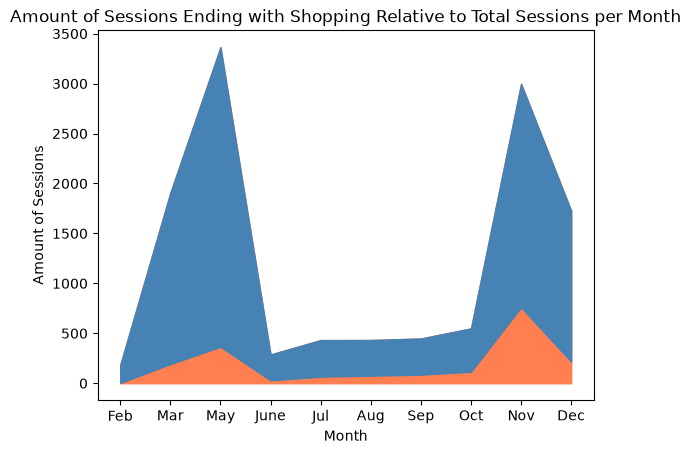

In [68]:
x = shopping_months_order["month"]
total_sessions = shopping_months_order["total_revenue"]
purchases = shopping_months_order["observations"]

plt.fill_between(
    x, 
    0, 
    purchases, 
    color = "coral"
)
plt.fill_between(
    x, 
    purchases, 
    total_sessions, 
    color = "steelblue"
)
plt.title("Amount of Sessions Ending with Shopping Relative to Total Sessions per Month")
plt.xlabel("Month")
plt.ylabel("Amount of Sessions")
plt.show()

### Distance to 'Special Day'

In [69]:
Special_day = (
    shoppers_intention_df.groupby("month")["special_day"]
    .mean()
    .rename("Closeness to Special Day")
    .reset_index()
)

Special_day_shopping = counts.merge(
    Special_day, 
    on = "month", 
    how = "inner", 
    validate = "one_to_one"
)

Special_day_shopping_order = Special_day_shopping.reindex(order)
Special_day_shopping_order


,month,observations,Closeness to Special Day
2,Feb,184,0.2
5,Mar,1907,0.0
6,May,3364,0.2
4,June,288,0.0
3,Jul,432,0.0
0,Aug,433,0.0
9,Sep,448,0.0
8,Oct,549,0.0
7,Nov,2998,0.0
1,Dec,1727,0.0


In [70]:
shoppers_intention_df[shoppers_intention_df['special_day'] > 0].groupby('month').count()

,administrative,administrative_duration,informational,informational_duration,product_related,product_related_duration,bounce_rates,exit_rates,page_values,special_day,operating_systems,browser,region,traffic_type,visitor_type,weekend,revenue
month,,,,,,,,,,,,,,,,,
Feb,79,79,79,79,79,79,79,79,79,79,79,79,79,79,79,79,79
May,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172
